<a href="https://colab.research.google.com/github/VishalK720/vishalcset343/blob/main/Lab_5_1037.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc,
    roc_auc_score
)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/dermatology/dermatology.data"
)

columns = [
    "erythema", "scaling", "definite_borders", "itching",
    "koebner_phenomenon", "polygonal_papules",
    "follicular_papules", "oral_mucosal_involvement",
    "knee_and_elbow_involvement", "scalp_involvement",
    "family_history", "melanin_incontinence",
    "eosinophils_infiltrate", "PNL_infiltrate",
    "fibrosis_papillary_dermis", "exocytosis", "acanthosis",
    "hyperkeratosis", "parakeratosis", "clubbing_rete_ridges",
    "elongation_rete_ridges", "thinning_suprapapillary_epidermis",
    "spongiform_pustule", "munro_microabcess",
    "focal_hypergranulosis", "disappearance_granular_layer",
    "vacuolisation_damage_basal_layer", "spongiosis",
    "saw_tooth_appearance_retes", "follicular_horn_plug",
    "perifollicular_parakeratosis",
    "inflammatory_monoluclear_infiltrate",
    "band_like_infiltrate", "age", "class"
]

df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully
Dataset shape: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

Number of rows: 366
Number of columns: 35

Column names:
['erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon', 'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement', 'knee_and_elbow_involvement', 'scalp_involvement', 'family_history', 'melanin_incontinence', 'eosinophils_infiltrate', 'PNL_infiltrate', 'fibrosis_papillary_dermis', 'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis', 'clubbing_rete_ridges', 'elongation_rete_ridges', 'thinning_suprapapillary_epidermis', 'spongiform_pustule', 'munro_microabcess', 'focal_hypergranulosis', 'disappearance_granular_layer', 'vacuolisation_damage_basal_layer', 'spongiosis', 'saw_tooth_appearance_retes', 'follicular_horn_plug', 'perifollicular_parakeratosis', 'inflammatory_monoluclear_infiltrate', 'band_like_infiltrate', 'age', 'class']

Data types:
erythema                                 int64
scaling                                  int64
definite_borders                         int64
itching   

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   erythema                             366 non-null    int64  
 1   scaling                              366 non-null    int64  
 2   definite_borders                     366 non-null    int64  
 3   itching                              366 non-null    int64  
 4   koebner_phenomenon                   366 non-null    int64  
 5   polygonal_papules                    366 non-null    int64  
 6   follicular_papules                   366 non-null    int64  
 7   oral_mucosal_involvement             366 non-null    int64  
 8   knee_and_elbow_involvement           366 non-null    int64  
 9   scalp_involvement                    366 non-null    int64  
 10  family_history                       366 non-null    int64  
 11  melanin_in

In [4]:
print("Summary statistics:")
display(df.describe().T)

print("\nMean of each feature:")
display(df.mean(numeric_only=True))

print("\nMedian of each feature:")
display(df.median(numeric_only=True))

print("\nStandard deviation:")
display(df.std(numeric_only=True))

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee_and_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0



Mean of each feature:


,0
erythema,2.068306
scaling,1.795082
definite_borders,1.549180
itching,1.366120
koebner_phenomenon,0.633880
polygonal_papules,0.448087
follicular_papules,0.166667
oral_mucosal_involvement,0.377049
knee_and_elbow_involvement,0.614754
scalp_involvement,0.519126



Median of each feature:


,0
erythema,2.0
scaling,2.0
definite_borders,2.0
itching,1.0
koebner_phenomenon,0.0
polygonal_papules,0.0
follicular_papules,0.0
oral_mucosal_involvement,0.0
knee_and_elbow_involvement,0.0
scalp_involvement,0.0



Standard deviation:


,0
erythema,0.664753
scaling,0.701527
definite_borders,0.907525
itching,1.138299
koebner_phenomenon,0.908016
polygonal_papules,0.957327
follicular_papules,0.570588
oral_mucosal_involvement,0.834147
knee_and_elbow_involvement,0.982979
scalp_involvement,0.905639


In [21]:
df = df.drop_duplicates().copy()

print("Missing values remaining:")
print(df.isnull().sum())

Missing values remaining:
erythema                               0
scaling                                0
definite_borders                       0
itching                                0
koebner_phenomenon                     0
polygonal_papules                      0
follicular_papules                     0
oral_mucosal_involvement               0
knee_and_elbow_involvement             0
scalp_involvement                      0
family_history                         0
melanin_incontinence                   0
eosinophils_infiltrate                 0
PNL_infiltrate                         0
fibrosis_papillary_dermis              0
exocytosis                             0
acanthosis                             0
hyperkeratosis                         0
parakeratosis                          0
clubbing_rete_ridges                   0
elongation_rete_ridges                 0
thinning_suprapapillary_epidermis      0
spongiform_pustule                     0
munro_microabcess              

In [6]:
feature_columns = df.drop(columns=["class"]).columns

Q1 = df[feature_columns].quantile(0.25)
Q3 = df[feature_columns].quantile(0.75)
IQR = Q3 - Q1

outlier_mask = (
    (df[feature_columns] < (Q1 - 1.5 * IQR)) |
    (df[feature_columns] > (Q3 + 1.5 * IQR))
)

print("Potential outliers per feature:")
display(outlier_mask.sum().sort_values(ascending=False))

print("\nNote: Dermatology attributes are mostly ordinal scores.")
print("Do not automatically delete valid scores as outliers.")

Potential outliers per feature:


,0
acanthosis,156
erythema,151
munro_microabcess,80
band_like_infiltrate,77
saw_tooth_appearance_retes,72
vacuolisation_damage_basal_layer,72
focal_hypergranulosis,71
spongiform_pustule,70
melanin_incontinence,70
polygonal_papules,69



Note: Dermatology attributes are mostly ordinal scores.
Do not automatically delete valid scores as outliers.


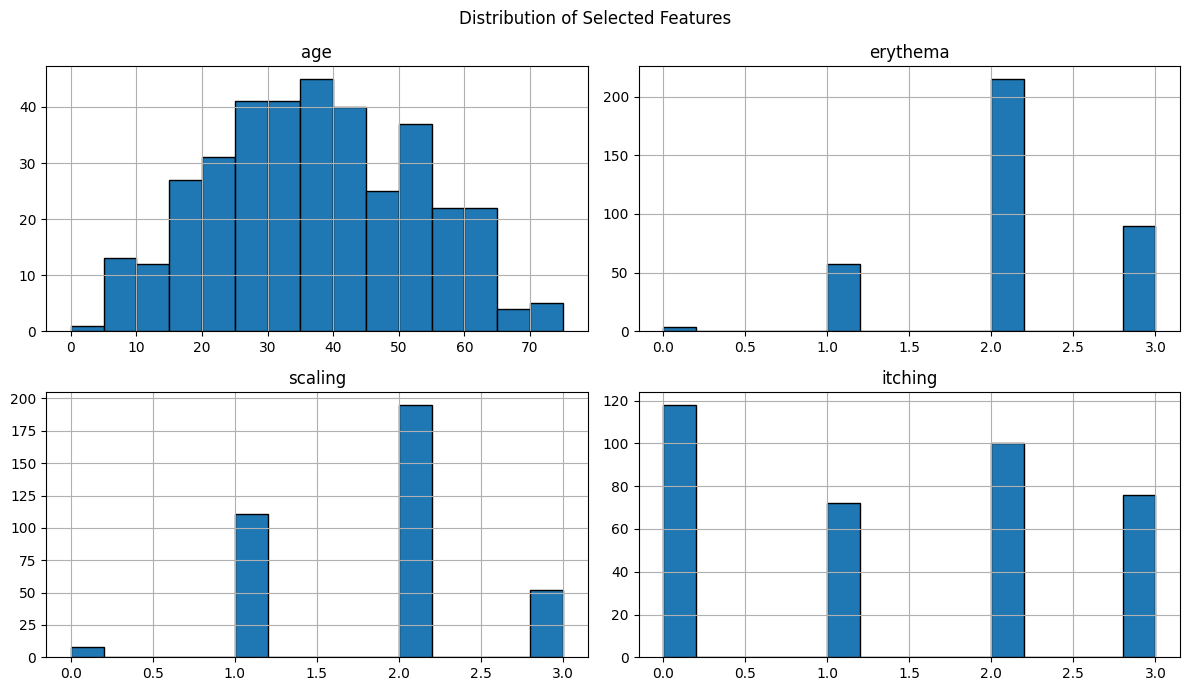

In [7]:
df[["age", "erythema", "scaling", "itching"]].hist(
    bins=15, figsize=(12, 7), edgecolor="black"
)

plt.suptitle("Distribution of Selected Features")
plt.tight_layout()
plt.show()

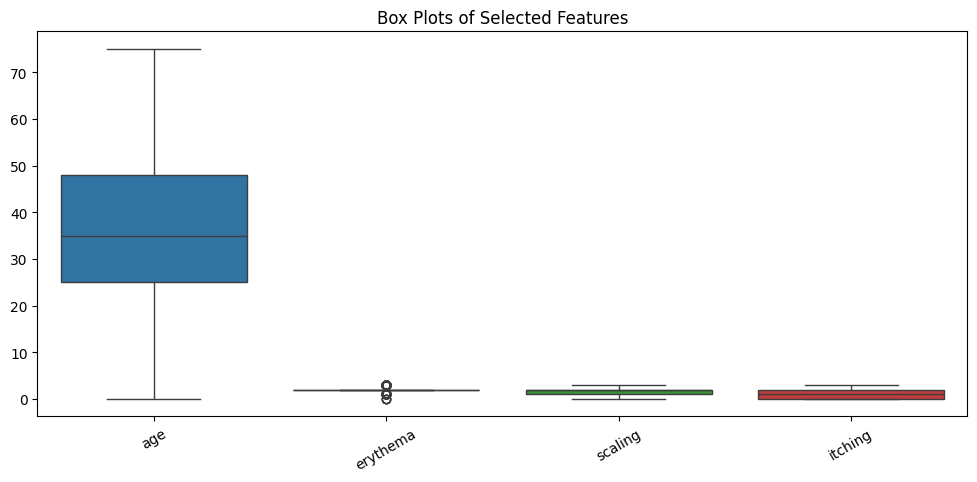

In [8]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df[["age", "erythema", "scaling", "itching"]]
)

plt.title("Box Plots of Selected Features")
plt.xticks(rotation=30)
plt.show()

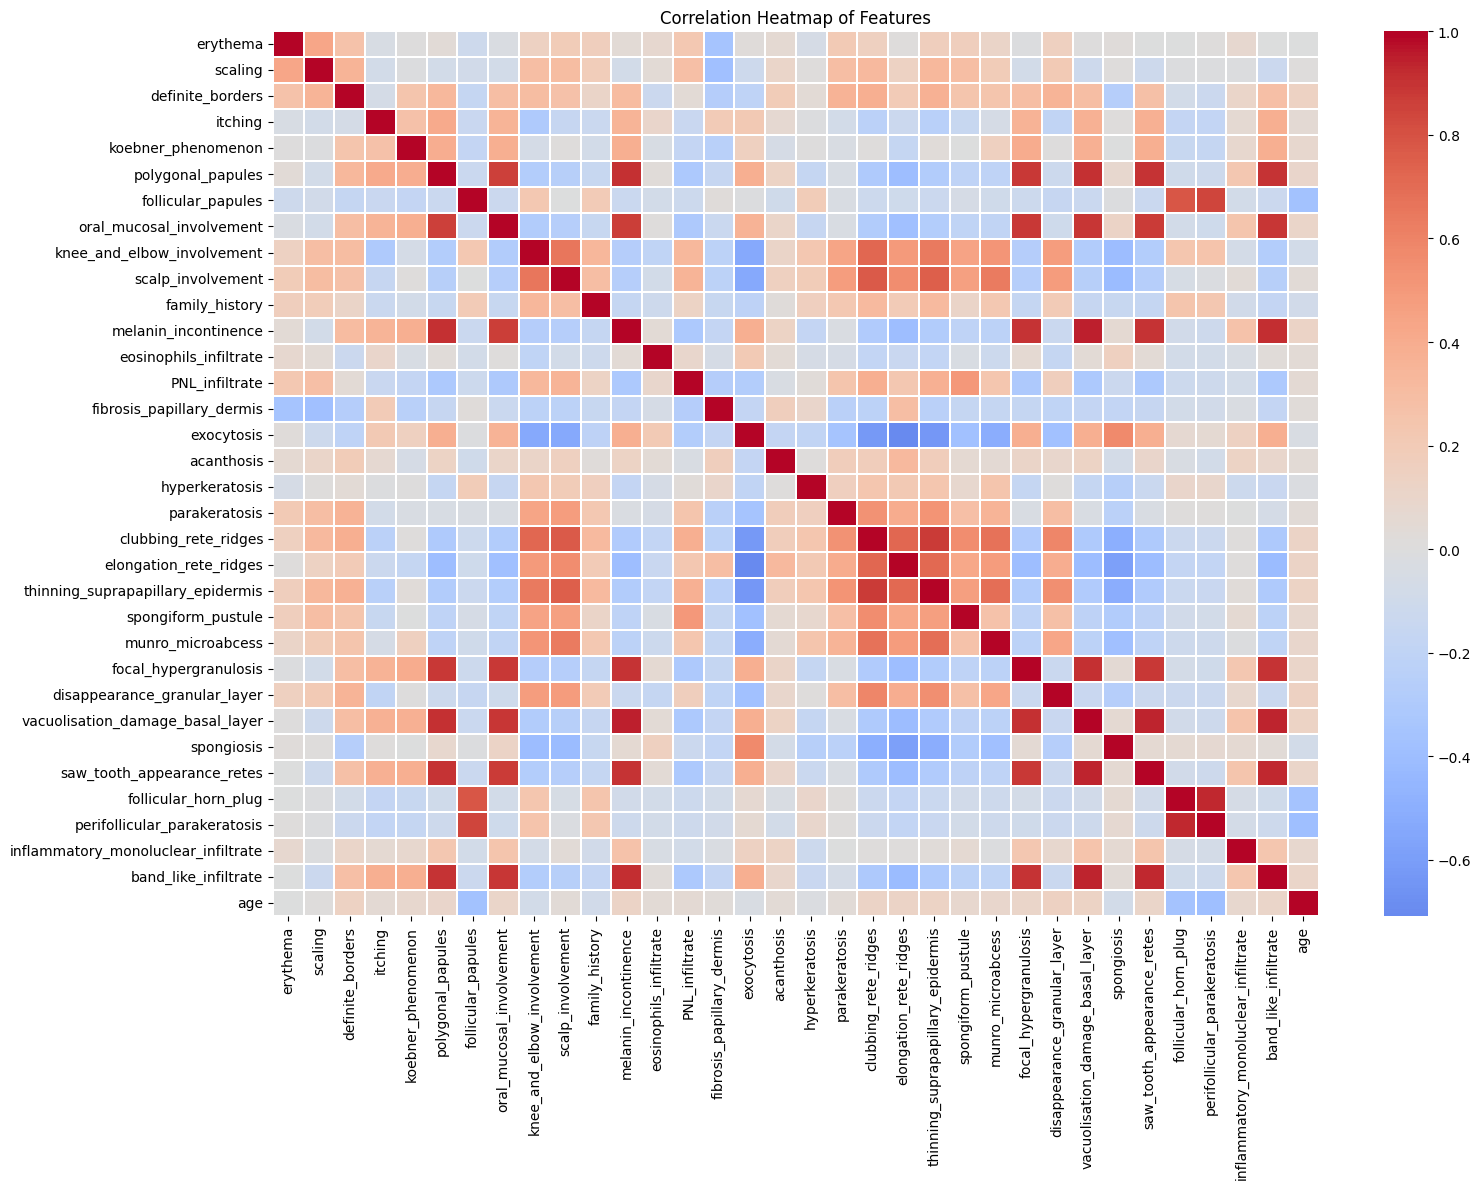

In [9]:
plt.figure(figsize=(16, 12))

correlation = df.drop(columns=["class"]).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Features")
plt.tight_layout()
plt.show()

Number of records in each class:


,count
class,
1,112
2,61
3,72
4,49
5,52
6,20


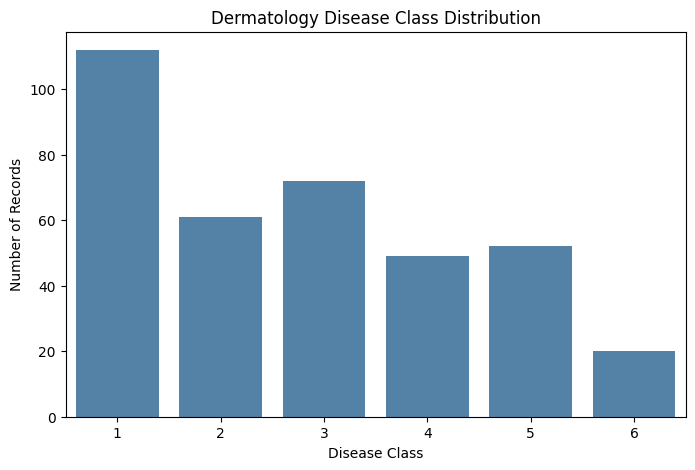


Class proportions:


,count
class,
1,30.60
2,16.67
3,19.67
4,13.39
5,14.21
6,5.46


In [10]:
class_counts = df["class"].value_counts().sort_index()

print("Number of records in each class:")
display(class_counts)

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="class", color="steelblue")

plt.title("Dermatology Disease Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Records")
plt.show()

print("\nClass proportions:")
display((class_counts / class_counts.sum() * 100).round(2))

In [11]:
X = df.drop(columns=["class"])
y = df["class"]

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

print("Original classes:", sorted(y.unique()))
print("Encoded classes:", sorted(np.unique(y_encoded)))
print("Number of features:", X.shape[1])
print("Number of target classes:", len(np.unique(y_encoded)))

Original classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Encoded classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Number of features: 34
Number of target classes: 6


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 292
Testing samples: 74

Training class distribution:
0    89
1    49
2    57
3    39
4    42
5    16
Name: count, dtype: int64

Testing class distribution:
0    23
1    12
2    15
3    10
4    10
5     4
Name: count, dtype: int64


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data standardized:", X_train_scaled.shape)
print("Testing data standardized:", X_test_scaled.shape)

Training data standardized: (292, 34)
Testing data standardized: (74, 34)


In [22]:
def make_scaled_model(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

models = {
    "Logistic Regression": make_scaled_model(
        LogisticRegression(max_iter=3000, random_state=42)
    ),
    "KNN": make_scaled_model(
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200, random_state=42
        ))
    ]),
    "SVM": make_scaled_model(
        SVC(probability=True, random_state=42)
    ),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42))
    ])
}

print("Models prepared with training-only preprocessing.")

Models prepared with training-only preprocessing.


In [15]:
results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-score (macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-score (macro)", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,SVM,0.9730,0.9722,0.9722,0.9697
1,Logistic Regression,0.9595,0.9615,0.9611,0.9574
2,Random Forest,0.9595,0.9545,0.9556,0.9545
3,KNN,0.9054,0.9071,0.9094,0.9034
4,Decision Tree,0.9324,0.9293,0.8778,0.8878


In [16]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test)

print("Best model by macro F1-score:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    labels=np.arange(len(encoder.classes_)),
    target_names=[str(c) for c in encoder.classes_],
    zero_division=0
))

Best model by macro F1-score: SVM

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      1.00      1.00        15
           4       0.83      1.00      0.91        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.97        74
   macro avg       0.97      0.97      0.97        74
weighted avg       0.98      0.97      0.97        74



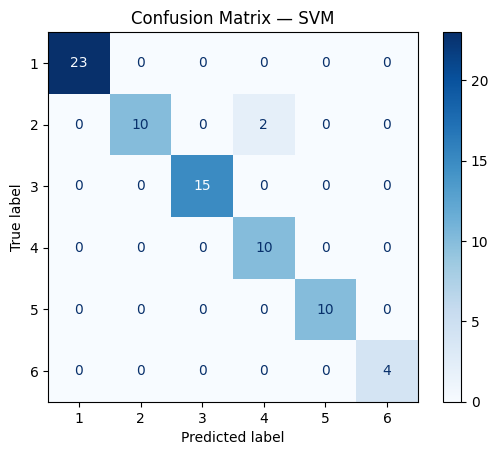

In [17]:
cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=np.arange(len(encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

Macro-average ROC-AUC: 0.9981


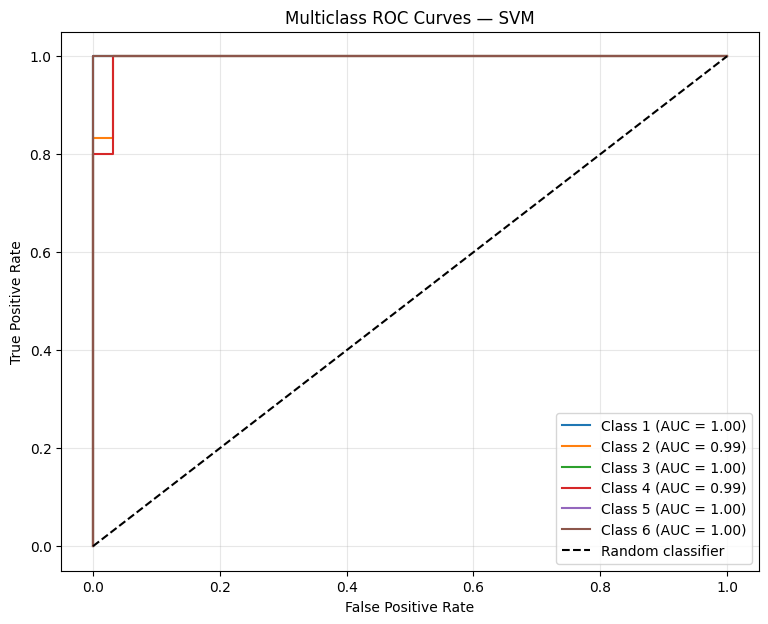

In [18]:
# Convert test labels to a one-vs-rest binary format
n_classes = len(encoder.classes_)

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

# Obtain predicted probabilities for each class
y_score = best_model.predict_proba(X_test)

# Calculate multiclass AUC
macro_auc = roc_auc_score(
    y_test_bin,
    y_score,
    average="macro",
    multi_class="ovr"
)

print(f"Macro-average ROC-AUC: {macro_auc:.4f}")

# Plot one ROC curve for each class
plt.figure(figsize=(9, 7))

for i, class_label in enumerate(encoder.classes_):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_score[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"Class {class_label} (AUC = {class_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"Multiclass ROC Curves — {best_model_name}")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

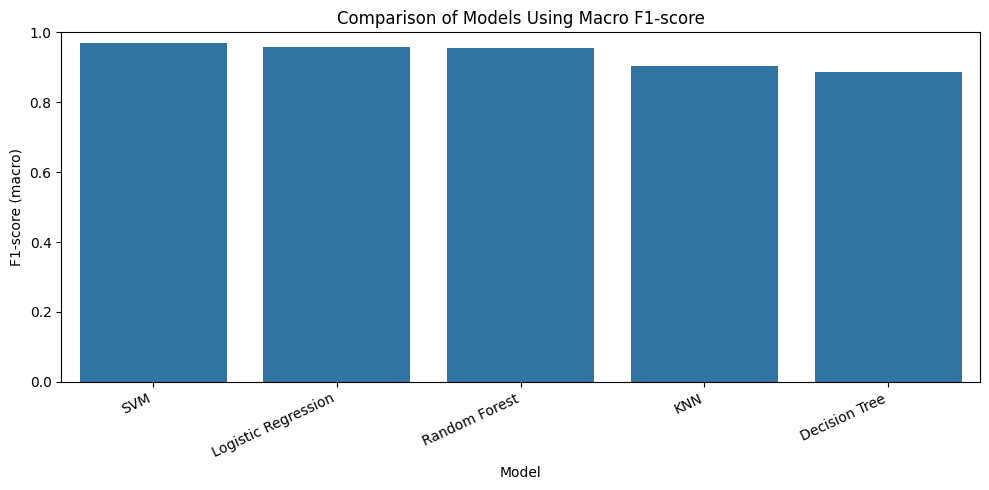

Final model comparison:


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,SVM,0.9730,0.9722,0.9722,0.9697
1,Logistic Regression,0.9595,0.9615,0.9611,0.9574
2,Random Forest,0.9595,0.9545,0.9556,0.9545
3,KNN,0.9054,0.9071,0.9094,0.9034
4,Decision Tree,0.9324,0.9293,0.8778,0.8878


In [19]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1-score (macro)"
)

plt.title("Comparison of Models Using Macro F1-score")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("Final model comparison:")
display(results_df.round(4))

In [20]:
best_row = results_df.iloc[0]

print("FINAL RESULTS")
print("-" * 40)
print("Best model by macro F1-score:", best_row["Model"])
print(f"Accuracy: {best_row['Accuracy']:.4f}")
print(f"Macro Precision: {best_row['Precision (macro)']:.4f}")
print(f"Macro Recall: {best_row['Recall (macro)']:.4f}")
print(f"Macro F1-score: {best_row['F1-score (macro)']:.4f}")
print(f"Macro ROC-AUC: {macro_auc:.4f}")

print("\nInterpretation:")
print(
    "The model with the highest macro F1-score is the leading model "
    "in this comparison. Review its class-wise scores and confusion "
    "matrix to identify strengths and weaknesses."
)

FINAL RESULTS
----------------------------------------
Best model by macro F1-score: SVM
Accuracy: 0.9730
Macro Precision: 0.9722
Macro Recall: 0.9722
Macro F1-score: 0.9697
Macro ROC-AUC: 0.9981

Interpretation:
The model with the highest macro F1-score is the leading model in this comparison. Review its class-wise scores and confusion matrix to identify strengths and weaknesses.
